# 정규분포·Z점수·중심극한정리

표준화는 단위 조정이며 정규분포로 만드는 작업이 아닙니다. 중심극한정리는 원자료가 아니라 표본평균의 분포에 관한 정리입니다.

**학습 목표:** 경험적 규칙, Z점수와 백분위, 정규성 진단과 p값, 중심극한정리

공식 → 직접 구현 또는 계산 → 라이브러리 대조 → 해석 순서로 학습합니다.

## 실행 준비

Python 3.11 이상, NumPy·pandas·SciPy·Matplotlib이 필요합니다. 없는 경우 별도 셀에서 `%pip install numpy pandas scipy matplotlib`을 한 번 실행하세요. 새 커널에서 위에서 아래로 실행합니다. 외부 데이터 다운로드는 없습니다. 그래프는 폰트 호환을 위해 영문 제목을 쓰고 해석은 한국어로 제공합니다.

**표기:** 기본 기술 분산은 ddof=0, 모집단 분산 추정·평균 추론은 ddof=1을 명시합니다. 난수는 seed=42(문제에 지정 시 해당 seed)입니다.

In [1]:
import math
from collections import Counter
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
# 외부 파일 없이 재현 가능한 학습용 가상 자료
x = np.array([12, 15, 14, 10, 18, 20, 22, 25, 30, 28], dtype=float)
y = np.array([2, 4, 6, 8, 10, 12, 14, 40], dtype=float)
plt.rcParams['axes.unicode_minus'] = False


## 1. 경험적 규칙

정규분포일 때 평균±1σ,2σ,3σ 안에 약 68.27%,95.45%,99.73%가 포함됩니다. 임의의 비대칭 분포에 그대로 적용하지 않습니다. IQR 경계가 약 99.3%를 포괄한다는 설명도 정규분포를 전제한 근사입니다.

In [2]:
def ranges_manual(mu,sigma):
    if sigma<0: raise ValueError('음수 표준편차')
    return [(mu-k*sigma,mu+k*sigma) for k in (1,2,3)]
print(ranges_manual(170,5))
for k in (1,2,3): print(k, stats.norm.cdf(k)-stats.norm.cdf(-k))

[(165, 175), (160, 180), (155, 185)]
1 0.6826894921370859
2 0.9544997361036416
3 0.9973002039367398


**해석 포인트:** 159 ~ 171,153 ~ 177,147 ~ 183cm입니다. 가운데 두 표준편차 구간 확률은 약 95.45%이며 관측 표본이 반드시 그 비율을 정확히 만족하는 것은 아닙니다.

**직접 확인:** 대응 실습의 문제 1에서 다른 입력으로 적용해 보세요.

## 2. Z점수와 백분위

z=(x−μ)/σ는 평균에서 몇 표준편차 떨어졌는지 표시합니다. σ=0인 상수 자료는 나눌 수 없습니다. 정규 누적확률로 계산한 백분위는 정규 가정 아래의 값이며 경험적 백분위와 다릅니다.

In [3]:
def z_manual(a):
    a=np.asarray(a,dtype=float); s=a.std(ddof=0)
    if s==0: raise ValueError('상수 자료')
    return (a-a.mean())/s
print(z_manual(x));assert np.allclose(z_manual(x),stats.zscore(x,ddof=0))
print(stats.norm.cdf(-.53)*100)

[-1.14402597 -0.68023166 -0.83482976 -1.45322217 -0.21643734  0.09275886
  0.40195507  0.86574938  1.6387399   1.32954369]
29.805596539487645


**해석 포인트:** z=1.5, 약 93.32백분위입니다. y 표준화는 평균 0, 표준편차 1을 만들지만 비대칭과 이상치 구조를 그대로 유지합니다.

**직접 확인:** 대응 실습의 문제 2에서 다른 입력으로 적용해 보세요.

## 3. 정규성 진단과 p값

히스토그램·Q-Q plot·Shapiro 검정을 함께 봅니다. 귀무가설은 정규분포에서 왔다는 것입니다. p값은 귀무가설 아래 관측값 이상으로 극단적인 통계량이 나올 확률이며 가설이 참일 확률이 아닙니다. p≥.05는 정규성 입증이 아닌 기각할 근거 부족입니다. 표본 크기에 따라 검정력이 달라집니다.

ShapiroResult(statistic=np.float64(0.9871510303173866), pvalue=np.float64(0.4478609485672087))


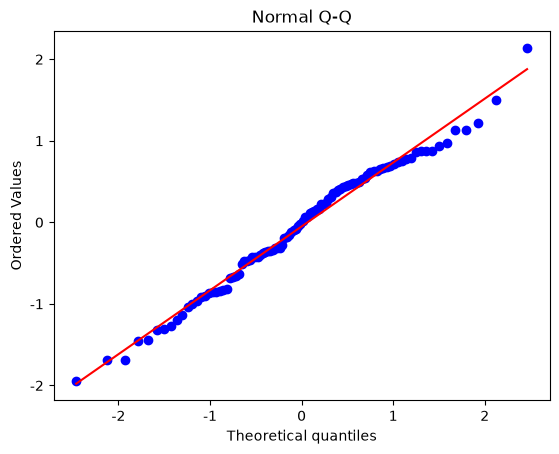

In [4]:
a=rng.normal(0,1,100)
print(stats.shapiro(a))
stats.probplot(a,dist='norm',plot=plt);plt.title('Normal Q-Q');plt.show()

**해석 포인트:** 큰 값 40 때문에 정규모형과 어긋나는 꼬리가 보입니다. 판단은 출력된 p값과 그래프에 근거합니다. 작은 표본에서는 결과가 불안정하며 독립성이 없는 자료는 이 검정만으로 분석 가정을 보장하지 못합니다.

**직접 확인:** 대응 실습의 문제 3에서 다른 입력으로 적용해 보세요.

## 4. 중심극한정리

독립·동일분포이고 유한한 분산을 갖는 표본에서 n이 커지면 표본평균의 표준화된 분포가 정규분포에 가까워집니다. n=30은 보편적 보증이 아닙니다. 지수분포 평균과 표준편차가 모두 2라면 표준오차는 2/√n입니다. 아래 예제는 지수분포에서 직접 독립 추출합니다.

5 1.9803016435259957 0.8777498887609049 0.8944271909999159
30 2.0060975188251344 0.3699780884596575 0.3651483716701107
100 1.9975352243167408 0.1970603708523229 0.2


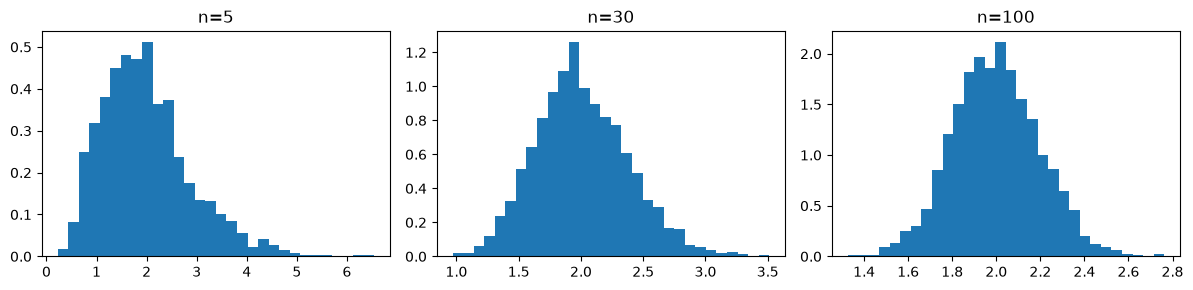

In [5]:
fig,axes=plt.subplots(1,3,figsize=(12,3))
for ax,n in zip(axes,[5,30,100]):
    means=rng.exponential(2,size=(2000,n)).mean(axis=1)
    ax.hist(means,bins=30,density=True);ax.set_title(f'n={n}')
    print(n, means.mean(),means.std(ddof=1),2/np.sqrt(n))
plt.tight_layout();plt.show()

**해석 포인트:** 표본평균 중심은 약 3에 머물고 n=100에서는 퍼짐이 줄어듭니다. 이론 표준오차는 약 1.342와 0.3입니다. 원래 지수분포 자체가 정규분포로 바뀐 것은 아닙니다.

**직접 확인:** 대응 실습의 문제 4에서 다른 입력으로 적용해 보세요.

## 복습 순서

1. 관측 대상과 통계량의 의미를 말로 설명합니다.
2. 분모·단위·독립성·분포 가정을 확인합니다.
3. 직접 계산과 라이브러리 결과를 비교합니다.
4. 코드 결과와 실제로 주장할 수 있는 범위를 구분합니다.

**학습 이동:** `Statistics_2_normal_clt.ipynb` → `Statistics_2_normal_clt_Practice.ipynb` → `Statistics_2_normal_clt_Answer.ipynb`.